# Power budget

A worked example of `quicksat`'s power budget: the sample satellite's generation and consumption over the scenario sample's three orbits, through the battery.

**Run all the cells.** The notebook reads the four files in `data/`, runs the scenario, works out the generation and the loads, and follows the battery's charge step by step. Below are the checks, the viewer, the power generated against the power consumed, the battery's charge, and where the energy goes in each orbit.

For how each part works, such as the losses, the battery and the checks, see `docs/power/power_budget_ref.ipynb`.

In [1]:
# Change log. LAST_CHANGE and CHANGE_NOTE are typed in by hand. Update them whenever
# the inputs change, such as a new battery, an efficiency, a margin or a new scenario, so that the figures below can be read
# against what produced them. The run time is recorded automatically, and says how
# stale the outputs stored in this notebook are relative to that last change.
from datetime import datetime

LAST_CHANGE = "2026-10-24"
CHANGE_NOTE = (
    "The scenario sample's three orbits, with the power sample's panels, a 1024 W h "
    "battery at 80% capacity, efficiencies of 0.95 to 0.97, the sixteen loads with "
    "their equipment margins, and a system margin of 5%. The loads are in two files, "
    "the payload's and the platform's, each with its own modes. The payload is in "
    "its imaging mode from the start of the turn into imaging."
)

print(f"last change  {LAST_CHANGE}")
print(f"             {CHANGE_NOTE}")
print(f"last run     {datetime.now().astimezone():%Y-%m-%d %H:%M %Z}")

last change  2026-10-24
             The scenario sample's three orbits, with the power sample's panels, a 1024 W h battery at 80% capacity, efficiencies of 0.95 to 0.97, the sixteen loads with their equipment margins, and a system margin of 5%. The loads are in two files, the payload's and the platform's, each with its own modes. The payload is in its imaging mode from the start of the turn into imaging.
last run     2026-10-24 19:57 CEST


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# quicksat is installed with pip. In a clone of the repository, use the package
# beside sample/ instead, so that it runs without installing. Either way the
# notebook runs in its own folder, and reads data/ beside it.
repo = Path.cwd().parents[1]
if (repo / "quicksat" / "__init__.py").exists():
    sys.path.insert(0, str(repo))

from quicksat.power.budget import run_budget
from quicksat.power.config import PowerSystem
from quicksat.power.consumption import PowerConsumption, run_consumption
from quicksat.power.generation import run_generation
from quicksat.power.plots import balance_plot, charge_plot
from quicksat.power.viewer import write_power_viewer
from quicksat.scenario.attitude_files import write_attitude_files
from quicksat.scenario.config import Scenario
from quicksat.scenario.run import run_scenario
from quicksat.utils.plot_helpers import STYLE

plt.style.use(STYLE)

## The inputs

The budget reads four files, from the power sample's own folder:

- `scenario.yaml`, a copy of the scenario sample, with the power sample's 3D model;
- `power_system.yaml`, the panels, the battery, the efficiencies of the power conditioning and the system margin;
- `payload_consumption.csv` and `platform_consumption.csv`, what each piece of equipment draws in each of its group's modes.

The battery is the mass budget's 12.5 kg of Saft VES16 cells: 8 in series and 8 strings in parallel, 1024 W h when new. 80% of it is left at the end of life, and it may go 30% deep, so its charge must stay above 70%.

In [3]:
DATA = Path("data")
run = run_scenario(Scenario.from_yaml_file(DATA / "scenario.yaml"))
power_system = PowerSystem.from_yaml_file(DATA / "power_system.yaml")
generation = run_generation(power_system, run)
consumption = {
    group: PowerConsumption.from_csv(DATA / f"{group}_consumption.csv")
    for group in ("payload", "platform")
}
loads = run_consumption(consumption, run)
budget = run_budget(power_system, generation, loads)

for note in generation.notes + loads.notes:
    print(note)
print("The budget closes." if budget.passed else "The budget does not close.")

The budget closes.


## The checks

- **Battery charge:** the charge never falls below the 70% that a 30% depth of discharge allows.
- **Energy balance:** each whole orbit has energy to spare. A run that starts with the battery full could pass the first check for a few orbits while losing energy every orbit.
- **Loads met:** the battery never runs flat.

In [4]:
pd.DataFrame([vars(check) for check in budget.checks]).style.hide(axis="index")

name,status,detail
Battery charge,ok,"The lowest charge is 83.6%, above the 70% that a 30% depth of discharge allows."
Energy balance,ok,Each of the 3 whole orbits has energy to spare: 7.0 W h at least.
Loads met,ok,The battery never runs flat.


## Visualising the budget in the Viewer

The cell below writes the viewer into `output/`: the page `power_viewer.html`, the run's `scenario.js`, and the budget's `power.js`. The page is the scenario viewer, with a Power tab: the power of each panel, the loads, the battery's charge, and the setup. Its Attitude tab shows the body's roll, pitch and yaw, its turn rate and its acceleration, and offers the attitude files below for download. Keep the three files together, and send the whole folder to share it.

In [5]:
OUTPUT = Path("output")
page = write_power_viewer(budget, OUTPUT)

# The path is relative to this folder, so the stored output shows no local folders
display(
    Markdown(
        f"**The viewer is written:** `{page}`\n\n"
        "Double-click it in your file manager to open it."
    )
)

**The viewer is written:** `output/power_viewer.html`

Double-click it in your file manager to open it.

## The attitude for other tools

The run works out the body's attitude, slews included, and the angle of each wing. The cell below writes them as ECSV files into `output/`, next to the viewer. Each is a table of text, with a header that says what its numbers mean:

- `attitude.ecsv`: the time, the quaternion `qx qy qz qw`, and the attitude in effect, or `slew`.
- `articulation_wing_+y.ecsv` and `articulation_wing_-y.ecsv`: the time, the wing's angle about its drive axis, and whether it is parked.

The quaternion has its scalar part last, and turns body vectors into GCRS. So in scipy, `Rotation.from_quat([qx, qy, qz, qw]).apply(v_body)` gives the vector in GCRS. The viewer's Attitude tab offers the same files for download. See "The attitude files" in `docs/scenario/scenario_ref.ipynb` for the details.

In [6]:
for path in write_attitude_files(run, OUTPUT):
    print(path)

output/attitude.ecsv
output/articulation_wing_+y.ecsv
output/articulation_wing_-y.ecsv


## Power generated and consumed

The power at the array's output, against the loads with all their margins. Above the loads, the surplus charges the battery, until it is full. Below them, in eclipse and in the dips of imaging, the battery makes up the rest.

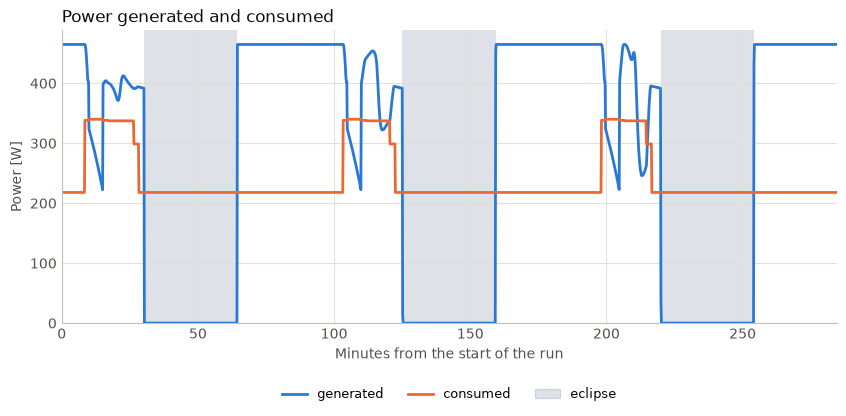

In [7]:
balance_plot(budget)
plt.show()

## The battery's charge

The charge, as a share of what the battery holds at the end of life, against the lowest it may reach.

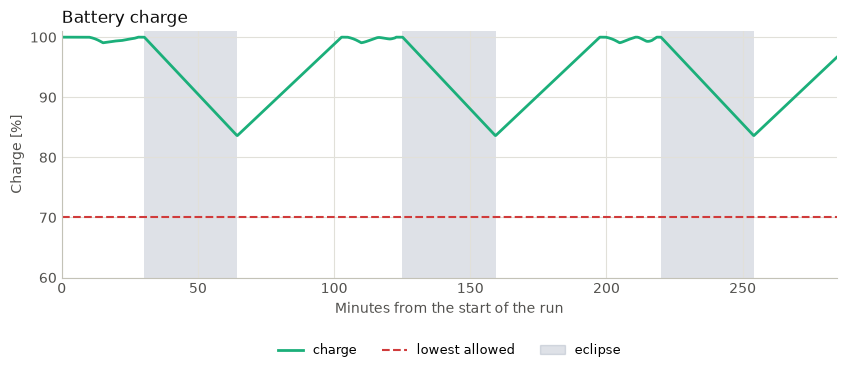

In [8]:
charge_plot(budget)
plt.show()

## Where the energy goes in each orbit

One row for each whole orbit, counted from the start of the run. The energy generated at the array's output goes to the loads, to the conditioning's losses, into the battery, or unused once the battery is full. The margin is the net energy into the battery, with the unused energy counted as if the battery had taken it: it must not be negative.

In [9]:
budget.orbit_table.style.hide(axis="index").format(
    {
        "generated [Wh]": "{:.1f}",
        "consumed [Wh]": "{:.1f}",
        "losses [Wh]": "{:.1f}",
        "unused [Wh]": "{:.1f}",
        "into battery [Wh]": "{:.1f}",
        "margin [Wh]": "{:.1f}",
        "charge at start [%]": "{:.1f}",
        "lowest charge [%]": "{:.1f}",
        "charge at end [%]": "{:.1f}",
    }
)

orbit,generated [Wh],consumed [Wh],losses [Wh],unused [Wh],into battery [Wh],margin [Wh],charge at start [%],lowest charge [%],charge at end [%]
1,435.5,383.1,40.8,39.3,-27.7,8.2,100.0,83.6,96.6
2,434.8,381.5,43.6,9.7,0.1,8.9,96.6,83.6,96.6
3,431.8,380.3,43.9,7.6,0.1,7.0,96.6,83.6,96.6


The conditioning's losses, one column for each path, in W h:

In [10]:
losses = budget.loss_table
losses.style.hide(axis="index").format(
    {column: "{:.1f}" for column in losses.columns if column != "orbit"}
)

orbit,array regulator [Wh],battery charge [Wh],battery discharge [Wh],distribution [Wh]
1,15.8,6.0,7.1,11.8
2,17.0,7.6,7.2,11.8
3,17.0,7.8,7.4,11.8


## Changing the sizing

Edit the files in `data/` and run the notebook again from the top. The notebook never writes them.

For example, raise `system_margin` to 10% in `power_system.yaml`. The loads then take more than the energy left over, by 7 to 9 W h an orbit, and the energy balance fails, although the charge still stays above 70% in these three orbits.

Or halve the battery to 512 W h, Saft's 8s4p pack. The charge then falls to about 67% at the end of each eclipse, below the limit.

Or let the wings track the sun in imaging too, in `scenario.yaml`. The array gives more, and the margin grows.